In [1]:
%load_ext autoreload
%autoreload 2
    
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
from tqdm import tqdm

import copy
import os
import sys

import networkx

import epimetheus as model
from epimetheus import summary, summary_latex
import read_data
import run_simulations

In [2]:
# Load saved models if available
run_C, run_Cg, run_CgR, run_S, run_CS, run_CSI, run_CD, run_CSD, run_CSIDT = \
    False, False, False, False, False, False, False, False, False

try:
    with open('series_C_new.pkl', 'rb') as file:
        series_C = pickle.load(file)
except:
    run_C = True
    
try:   
    with open('series_Cg_new.pkl', 'rb') as file:
        series_Cg = pickle.load(file)
except:
    run_Cg = True
    
try:
    with open('series_CgR_new.pkl', 'rb') as file:
        series_CgR = pickle.load(file)
except:
    run_CgR = True

try:
    with open('series_S_new.pkl', 'rb') as file:
        series_S = pickle.load(file)
except:
    run_S = True

try:
    with open('series_CS_new.pkl', 'rb') as file:
        series_CS = pickle.load(file)
except:
    run_CS = True

try:
    with open('series_CSI_new.pkl', 'rb') as file:
        series_CSI = pickle.load(file)
except:
    run_CSI = True

try:
    with open('series_CD_new.pkl', 'rb') as file:
        series_CD = pickle.load(file)
except:
    run_CD = True

try:
    with open('series_CSD_new.pkl', 'rb') as file:
        series_CSD = pickle.load(file)
except:
    run_CSD = True

try:
    with open('series_CSIDT_new.pkl', 'rb') as file:
        series_CSIDT = pickle.load(file)
except:
    run_CSIDT = True

In [3]:
# Load case data and any other required geodata:
try:
    with open('rki_data.pkl', 'rb') as file:
        rki_data = pickle.load(file)
except:
    rki_data = read_data.case_data()
    with open('rki_data.pkl', 'wb') as file:
        pickle.dump(rki_data, file)

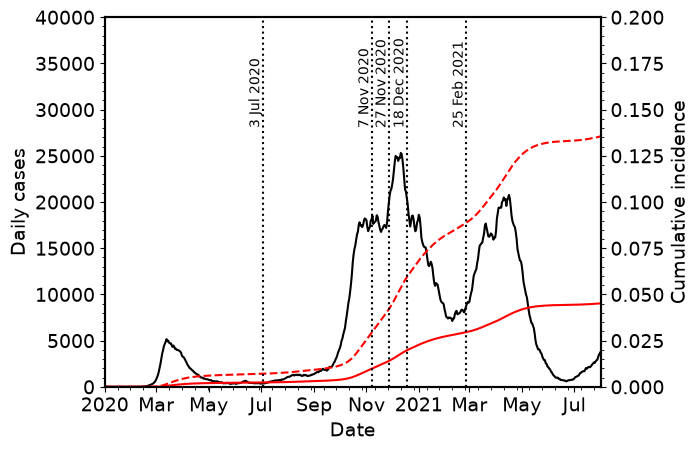

In [4]:
# Overview of epidemic until summer 2021
rki_data.plot_overview()
plt.savefig ('plot_overview.pdf', bbox_inches='tight' )

Matching fraction of cumulative infections relative to outbreak size for data and simulations.


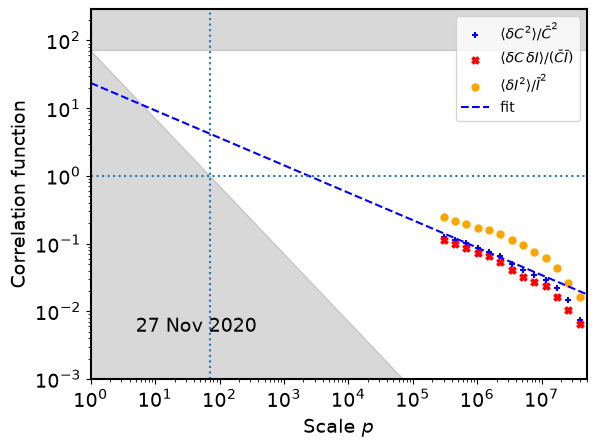

In [5]:
# Spectrum of observed data and power-law extrapolation
model.plot_spectra(rki_data, 330, 420, [], reporting_factor=1, norm='relative',\
                  label = None)
!mv spectrum.pdf spectrum_rep1.pdf

In [6]:
# We need the effective reproduction number as input for Series CgR.
# A simple approximation is sufficient, no need to work with the exact convolution kernel.
ncase_all = np.sum(rki_data.cases,axis=0)
rtest = ncase_all[4:]/ncase_all[:-4]

/var/folders/lg/fgs0zdfx66s672t95kd1pkpm0000gp/T/ipykernel_2947/2359336611.py:4: RuntimeWarning: invalid value encountered in divide
  rtest = ncase_all[4:]/ncase_all[:-4]


In [7]:
# Note the dates for time steps that we consider in our analysis
ii_07_nov_20 = 310
ii_18_dec_20 = 351
ii_25_feb_21 = 420
print(pd.to_datetime(rki_data.date[420],origin='julian',unit='D'))
print(pd.to_datetime(rki_data.date[310],origin='julian',unit='D'))
print(pd.to_datetime(rki_data.date[351],origin='julian',unit='D'))

2021-02-25 00:00:00
2020-11-07 00:00:00
2020-12-18 00:00:00


In [8]:
# Compute observed temporal autocorrelation functions
ilast = ii_25_feb_21
win = 40

i_ac1 = ii_07_nov_20
ac1_obs = model.autocorrelation_observed(rki_data.cases, rki_data.pop0[:,0], i_ac1, window=win)
frac_ac1 = rki_data.Cav[i_ac1,-1]/rki_data.Cav[ilast,-1]
print("Fraction of outbreak size at t_AC1:", frac_ac1)

i_ac2 = ii_18_dec_20
ac2_obs = model.autocorrelation_observed(rki_data.cases, rki_data.pop0[:,0], i_ac2, window=win)
frac_ac2 = rki_data.Cav[i_ac2,-1]/rki_data.Cav[ilast,-1]
print("Fraction of outbreak size at t_AC2:", frac_ac2)

Fraction of outbreak size at t_AC1: 0.32844232494257974
Fraction of outbreak size at t_AC2: 0.6655978063934561


/Users/bmueller/turbulent_epidemics/analysis/epimetheus.py:991: RuntimeWarning: invalid value encountered in divide
  dI = I / Iav[np.newaxis,:] * pop[:,np.newaxis]


Text(0, 0.5, 'time for C')

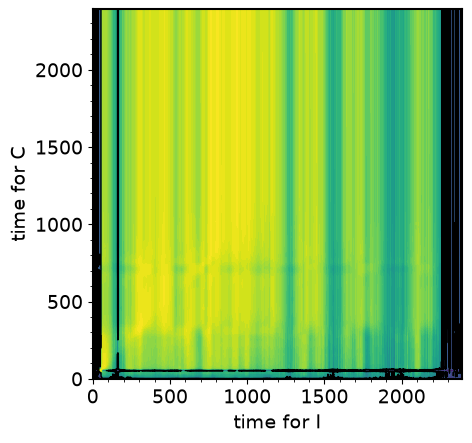

In [9]:
# Autcorrelation between any two time steps
acc = model.autocorrelation_observed2 (rki_data.cases, rki_data.pop0[:,0])

plt.contourf(acc['dCdI'][:,:],levels=50)
plt.contour(acc['dCdI'],levels=[0.3],colors='k',linewidths=1)
plt.gca().set_aspect(1)
plt.minorticks_on()
plt.xlabel('time for I')
plt.ylabel('time for C')

Simulations

In [10]:
l2pop = 22 # log_2 of population size
r0 = 1.4   # calibration value for R0

In [11]:
if run_C:
    series_C = run_simulations.run_series (l2pop = l2pop, r0 = r0,
                degree_dist = 'uniform', exc_contacts = 12, alpha_pareto = 2.1, \
                f_cluster = [0, 0.3, 0.8, 0.9, 0.95], c_alpha = 0.5, \
                gamma_c = 0.0, gamma_r = 0.0, homogeneous=False, \
                sus_type = 'uniform', p_sus = (0.4,2.5), p_scal = 0.0, \
                dur_type = 'uniform', p_dur = 0.2, imm_type = 'uniform', p_imm = (2.5,4), \
                frac_ac1 = frac_ac1, frac_ac2 = frac_ac2, seed = 26082026)
    
    with open('series_C_new.pkl', 'wb') as file:
        pickle.dump(series_C, file)

In [12]:
if run_Cg:
    gamma_c = np.array([0, 0.3, 0.6, 0.9, 1.1, 1.2])
    gamma_r = 2/9 * gamma_c
    series_Cg = run_simulations.run_series(l2pop = l2pop, r0 = r0, \
                degree_dist = 'uniform', exc_contacts = 12, \
                alpha_pareto = 2.1, f_cluster = 0.0, c_alpha = 0.5, \
                gamma_c = gamma_c.tolist(), gamma_r = gamma_r.tolist(), homogeneous=False, \
                sus_type = 'uniform', p_sus = (0.4,2.5), p_scal = 0.0, \
                dur_type = 'uniform', p_dur = 0.2, imm_type = 'uniform', p_imm = (2.5,4), \
                frac_ac1 = frac_ac1, frac_ac2 = frac_ac2, seed = 26082026)
    
    with open('series_Cg_new.pkl', 'wb') as file:
        pickle.dump(series_Cg, file)

In [13]:
if run_S:
    series_S = run_simulations.run_series (l2pop = l2pop, r0 = r0, \
                degree_dist = 'uniform', exc_contacts = 12, \
                alpha_pareto = 2.1, f_cluster = 0.0, c_alpha = 0.5, \
                gamma_c = 0.0, gamma_r = 0.0, homogeneous=False, \
                sus_type = 'uniform', p_sus = (0.4,2.5), p_scal = [0, 0.04, 0.08, 0.12, 0.16, 0.2, 0.24], \
                dur_type = 'uniform', p_dur = 0.2, imm_type = 'uniform', p_imm = (2.5,4), \
                frac_ac1 = frac_ac1, frac_ac2 = frac_ac2, seed = 26082026)
    
    with open('series_S_new.pkl', 'wb') as file:
        pickle.dump(series_S, file)

In [14]:
if run_CS:
    series_CS = run_simulations.run_series (l2pop = l2pop, r0 = r0, \
                degree_dist = 'uniform', exc_contacts = 12, \
                alpha_pareto = 2.1, f_cluster = 0.9, c_alpha = 0.5, \
                gamma_c = 0.0, gamma_r = 0.0, homogeneous=False, \
                sus_type = 'uniform', p_sus = (0.4,2.5), p_scal = [0, 0.04, 0.08, 0.12, 0.16, 0.2, 0.24], \
                dur_type = 'uniform', p_dur = 0.2, imm_type = 'uniform', p_imm = (2.5,4), \
                frac_ac1 = frac_ac1, frac_ac2 = frac_ac2, seed = 26082026)
    
    with open('series_CS_new.pkl', 'wb') as file:
        pickle.dump(series_CS, file)

In [15]:
if run_CSI:
    series_CSI = run_simulations.run_series (l2pop = l2pop, r0 = r0, \
                degree_dist = 'uniform', exc_contacts = 12, \
                alpha_pareto = 2.1, f_cluster = 0.9, c_alpha = 0.5, \
                gamma_c = 0.0, gamma_r = 0.0, homogeneous=False, \
                sus_type = 'gamma', p_sus = [(x,1/x) for x in [0.25, 0.5, 1, 2, 4]], p_scal = 0.2, \
                dur_type = 'uniform', p_dur = 0.2, imm_type = 'uniform', p_imm = (2.5,4), \
                frac_ac1 = frac_ac1, frac_ac2 = frac_ac2, seed = 26082026)
    
    with open('series_CSI_new.pkl', 'wb') as file:
        pickle.dump(series_CSI, file)

In [16]:
if run_CD:
    series_CD = run_simulations.run_series (l2pop = l2pop, r0 = r0, \
                degree_dist = 'pareto', exc_contacts = 12, 
                alpha_pareto = [1.6, 2.1, 2.6, 3.1], f_cluster = 0.9, c_alpha = 0.5, \
                gamma_c = 0.0, gamma_r = 0.1, homogeneous=False, \
                sus_type = 'uniform', p_sus = (0.5,2), p_scal = 0.0, \
                dur_type = 'uniform', p_dur = 0.2, imm_type = 'uniform', p_imm = (2.5,4), \
                frac_ac1 = frac_ac1, frac_ac2 = frac_ac2, seed = 26082026)
    
    with open('series_CD_new.pkl', 'wb') as file:
        pickle.dump(series_CD, file)

In [17]:
if run_CSD:
    series_CSD = run_simulations.run_series (l2pop = l2pop, r0 = r0, \
                degree_dist = 'pareto', exc_contacts = 12, \
                alpha_pareto = [1.6, 2.1, 2.6, 3.1], f_cluster = 0.9, c_alpha = 0.5, \
                gamma_c = 0.0, gamma_r = 0.1, homogeneous=False, \
                sus_type = 'uniform', p_sus = (0.5,2), p_scal = 0.1, \
                dur_type = 'uniform', p_dur = 0.2, imm_type = 'uniform', p_imm = (2.5,4), \
                frac_ac1 = frac_ac1, frac_ac2 = frac_ac2, seed = 26082026)
    
    with open('series_CSD_new.pkl', 'wb') as file:
        pickle.dump(series_CSD, file)

In [18]:
if run_CSIDT:
    series_CSIDT = run_simulations.run_series (l2pop = l2pop, r0 = 2.6, \
                degree_dist = 'pareto', exc_contacts = 12, \
                alpha_pareto = 2.1, f_cluster = 0.9, c_alpha = 0.5, \
                gamma_c = 0.0, gamma_r = 0.1, homogeneous=False, \
                sus_type = 'gamma', p_sus = (0.5,2), p_scal = 0.2, k_tra = [None, 1, 1/3], \
                dur_type = 'uniform', p_dur = 0.2, imm_type = 'uniform', p_imm = (2.5,4), \
                frac_ac1 = frac_ac1, frac_ac2 = frac_ac2, seed = 11082026, \
                calibration_point = 'infections', c_cal=1e-4)
    
    with open('series_CSIDT_new.pkl', 'wb') as file:
        pickle.dump(series_CSIDT, file)

In [19]:
if run_CgR:
    series_CgR = run_simulations.run_CgR (l2pop = l2pop, rtest = rtest, Iav_ini = 3*rki_data.Iav[183,0], \
                                          frac_ac1 = frac_ac1, frac_ac2 = frac_ac2, \
                                          win = 40, seed = 11082026)
    
    with open('series_CgR_new.pkl', 'wb') as file:
        pickle.dump(series_CgR, file)

Generate plots

Matching fraction of cumulative infections relative to outbreak size for data and simulations.
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.324364
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.347391
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.354408
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.364271
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.434219
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.482851


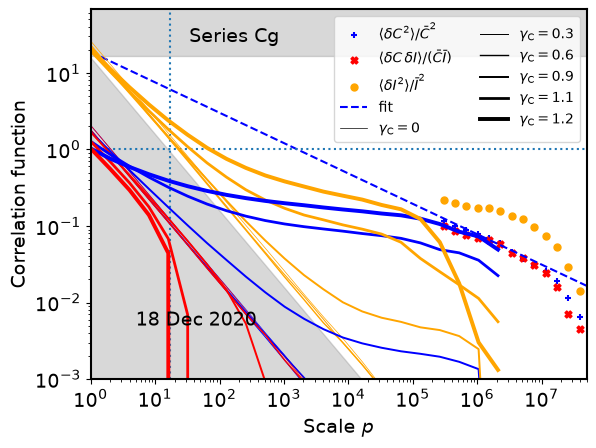

Matching fraction of cumulative infections relative to outbreak size for data and simulations.
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.324364
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.355823
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.394568
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.408869
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.524426


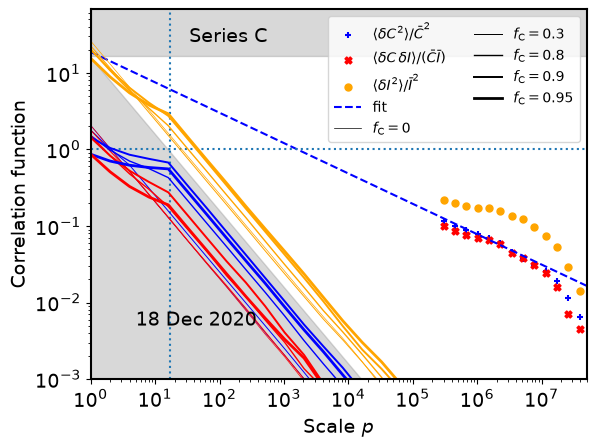

Matching fraction of cumulative infections relative to outbreak size for data and simulations.
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.324364
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.340232
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.329369
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.300335
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.277785
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.241092
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.193966


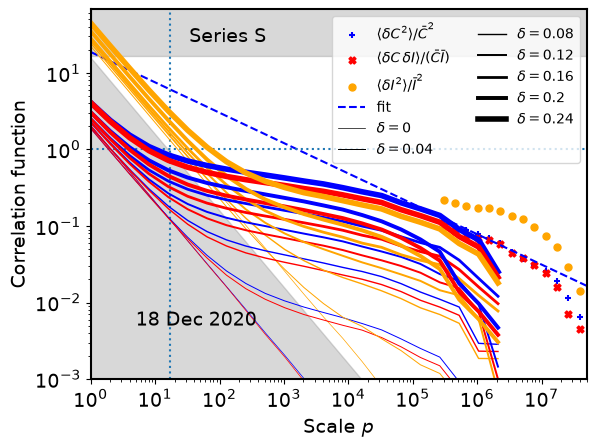

Matching fraction of cumulative infections relative to outbreak size for data and simulations.
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.485801
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.495233
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.440921
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.372820
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.307553
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.178072
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.240747


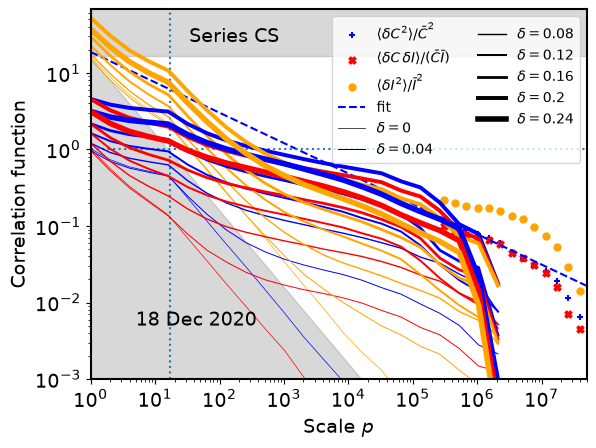

Matching fraction of cumulative infections relative to outbreak size for data and simulations.
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.126105
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.183361
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.165991
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.222099
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.233845


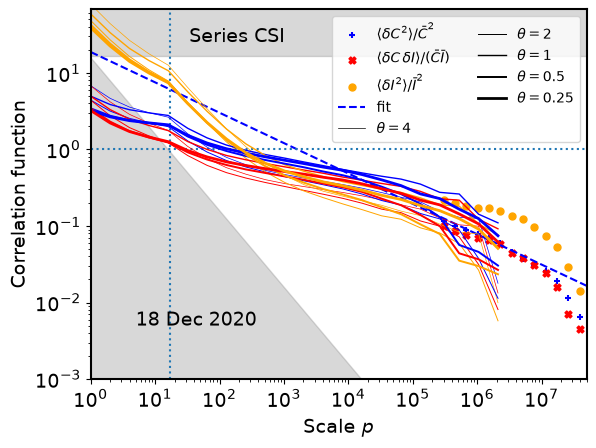

Matching fraction of cumulative infections relative to outbreak size for data and simulations.
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.191506
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.171043
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.202780
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.257422


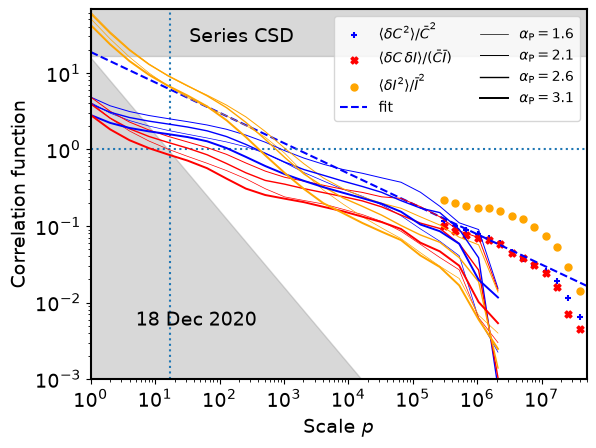

Matching fraction of cumulative infections relative to outbreak size for data and simulations.
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.233179
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.275510
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.301112
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.324480


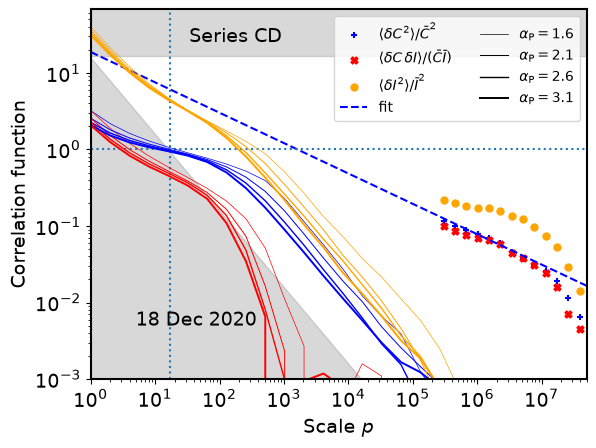

Matching fraction of cumulative infections relative to outbreak size for data and simulations.
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.186683
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.121307
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.120088


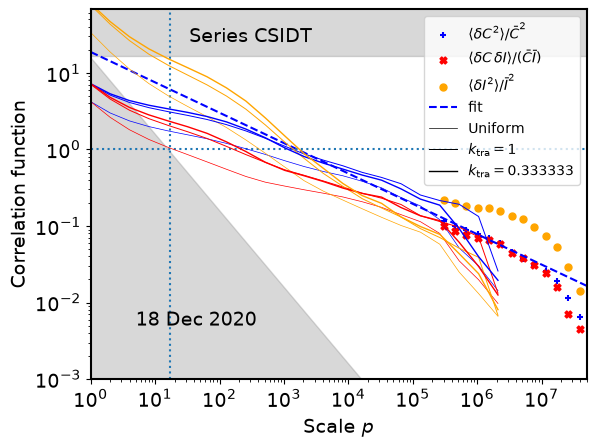

In [20]:
model.plot_spectra(rki_data, ii_18_dec_20, ii_25_feb_21, series_Cg, \
                   variable = (r'\gamma_\mathrm{C}','gamma_c'), \
                   reporting_factor=3, norm='relative',
                   label = 'Cg', ncol = 2)
model.plot_spectra(rki_data, ii_18_dec_20, ii_25_feb_21, series_C, \
                   variable = (r'f_\mathrm{C}','f_cluster'), \
                   reporting_factor=3, norm='relative',\
                   label = 'C', ncol=2)
model.plot_spectra(rki_data, ii_18_dec_20, ii_25_feb_21, series_S, \
                   variable = (r'\delta', 'p_scal'), \
                   reporting_factor=3, norm='relative',\
                   label = 'S', ncol=2)
model.plot_spectra(rki_data, ii_18_dec_20, ii_25_feb_21, series_CS, \
                   variable = (r'\delta', 'p_scal'), \
                   reporting_factor=3, norm='relative',\
                   label = 'CS', ncol=2)
model.plot_spectra(rki_data, ii_18_dec_20, ii_25_feb_21, series_CSI, \
                   variable = (r'\theta', 'p_sus'), \
                   reporting_factor=3, norm='relative',\
                   label = 'CSI', ncol=2)
model.plot_spectra(rki_data, ii_18_dec_20, ii_25_feb_21, series_CSD, \
                   variable = (r'\alpha_\mathrm{P}','alpha_pareto'), \
                   reporting_factor=3, norm='relative', \
                   label = 'CSD', ncol=2)
model.plot_spectra(rki_data, ii_18_dec_20, ii_25_feb_21, series_CD, \
                   variable = (r'\alpha_\mathrm{P}','alpha_pareto'), \
                   reporting_factor=3, norm='relative',\
                   label = 'CD', ncol=2)
model.plot_spectra(rki_data, ii_18_dec_20, 420, series_CSIDT, \
                   variable = (r'k_\mathrm{tra}','k_tra'), \
                   reporting_factor=3, norm='relative', \
                   label = 'CSIDT', ncol=1)

Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.


/Users/bmueller/turbulent_epidemics/analysis/epimetheus.py:881: RuntimeWarning: invalid value encountered in divide
  plt.plot(data.Cav[:,-1]/data.Cav[ilast,-1],data.dCdI[:,0]/data.Cav[:,0]/data.Iav[:,0],color='r',linestyle='dashed', \
/Users/bmueller/turbulent_epidemics/analysis/epimetheus.py:886: RuntimeWarning: invalid value encountered in divide
  plt.plot(data.Cav[:,-1]/data.Cav[ilast,-1],data.dI2[:,0]/data.Iav[:,0]**2,color='orange',linestyle='dashed',\


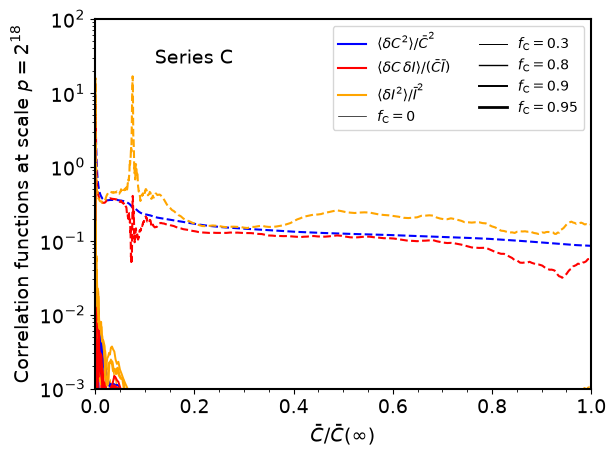

Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.


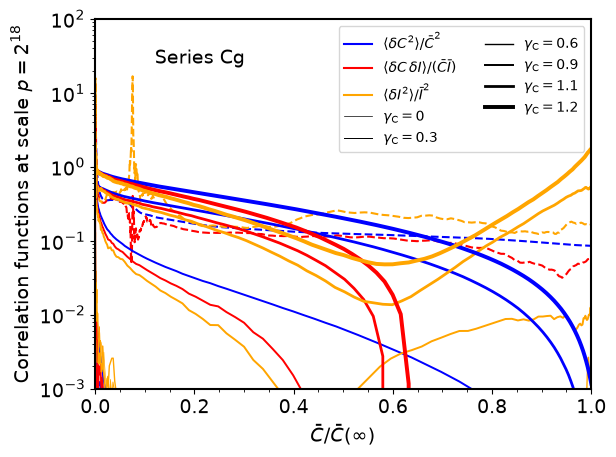

Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.


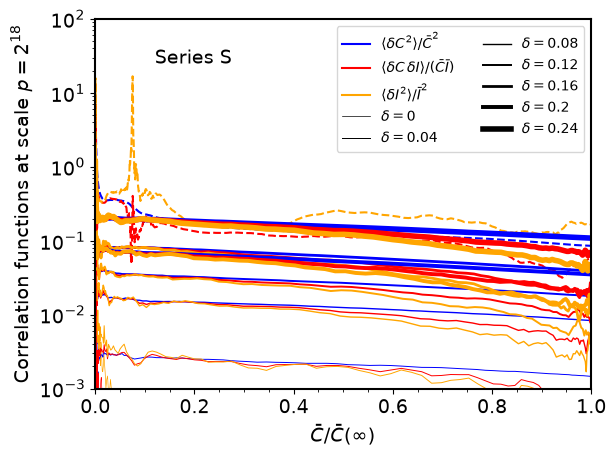

Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.


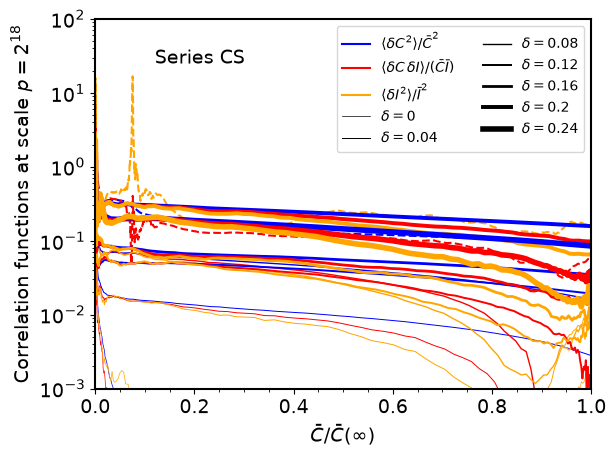

Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.


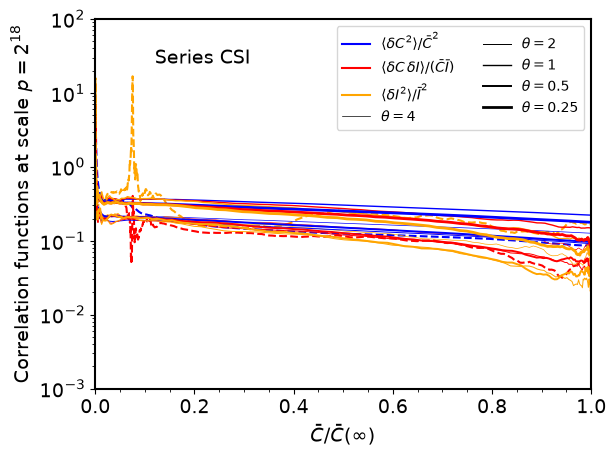

Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.


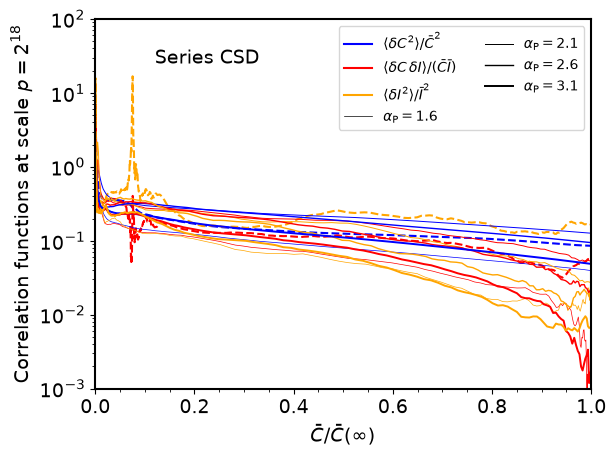

Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.


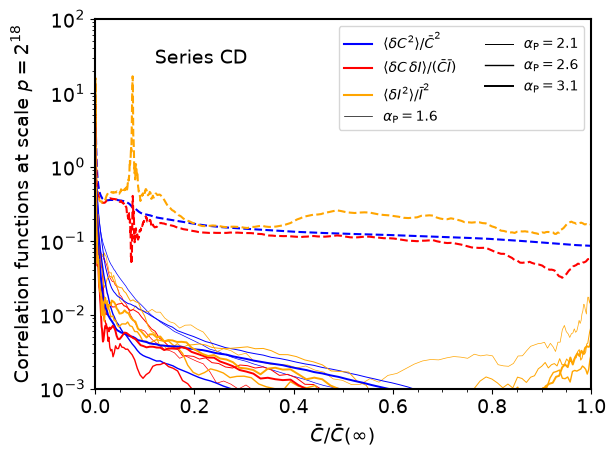

Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.


/Users/bmueller/turbulent_epidemics/analysis/epimetheus.py:897: RuntimeWarning: invalid value encountered in divide
  plt.plot(m.C/m.C[-1],m.dci[:,p_sim]/m.cav[:,p_sim]/m.iav[:,p_sim],color='r',linewidth=ithi)
/Users/bmueller/turbulent_epidemics/analysis/epimetheus.py:899: RuntimeWarning: invalid value encountered in divide
  plt.plot(m.C/m.C[-1],m.di2[:,p_sim]/m.iav[:,p_sim]**2,color='orange',linewidth=ithi)


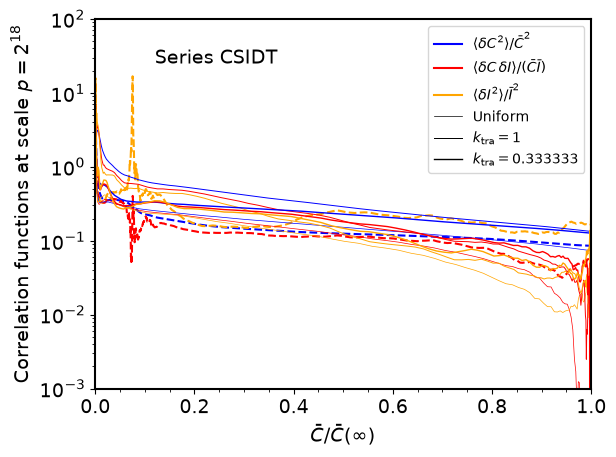

In [21]:
model.plot_spec_fixed_scale(rki_data, ii_25_feb_21, series_C[:], \
                            variable = (r'f_\mathrm{C}','f_cluster'), \
                            logx=False,p_sim=18, label ='C', ncol=2)
plt.ylim(1e-3,1e2)
plt.savefig('fluc_time_p22_C.pdf')
plt.show()

model.plot_spec_fixed_scale(rki_data, ii_25_feb_21, series_Cg[:], \
                            variable = (r'\gamma_\mathrm{C}', 'gamma_c'), \
                            logx=False,p_sim=18, label ='Cg', ncol=2)
plt.ylim(1e-3,1e2)
plt.savefig('fluc_time_p22_Cg.pdf')
plt.show()

model.plot_spec_fixed_scale(rki_data, ii_25_feb_21, series_S[:], \
                            variable = (r'\delta','p_scal'), \
                            logx=False,p_sim=18, label ='S', ncol=2)
plt.ylim(1e-3,1e2)
plt.savefig('fluc_time_p22_S.pdf')
plt.show()

model.plot_spec_fixed_scale(rki_data, ii_25_feb_21, series_CS[:], \
                            variable = (r'\delta','p_scal'), \
                            logx=False,p_sim=18, label ='CS', ncol=2)
plt.ylim(1e-3,1e2)
plt.savefig('fluc_time_p22_CS.pdf')
plt.show()


model.plot_spec_fixed_scale(rki_data, ii_25_feb_21, series_CSI[:], \
                            variable = (r'\theta','p_sus'), \
                            logx=False,p_sim=18, label ='CSI', ncol=2)
plt.ylim(1e-3,1e2)
plt.savefig('fluc_time_p22_CSI.pdf')
plt.show()

model.plot_spec_fixed_scale(rki_data, ii_25_feb_21, series_CSD[:], \
                            variable = (r'\alpha_\mathrm{P}', 'alpha_pareto'), \
                            logx=False,p_sim=18, label ='CSD', ncol=2)
plt.ylim(1e-3,1e2)
plt.savefig('fluc_time_p22_CSD.pdf')
plt.show()

model.plot_spec_fixed_scale(rki_data, ii_25_feb_21, series_CD[:], \
                            variable = (r'\alpha_\mathrm{P}', 'alpha_pareto'), \
                            logx=False,p_sim=18, label ='CD', ncol=2)
plt.ylim(1e-3,1e2)
plt.savefig('fluc_time_p22_CD.pdf')
plt.show()


model.plot_spec_fixed_scale(rki_data, ii_25_feb_21, series_CSIDT, \
                            variable = (r'k_\mathrm{tra}', 'k_tra'), \
                            logx=False,p_sim=18, label ='CSIDT')
plt.ylim(1e-3,1e2)
plt.savefig('fluc_time_p22_CSIDT.pdf')
plt.show()

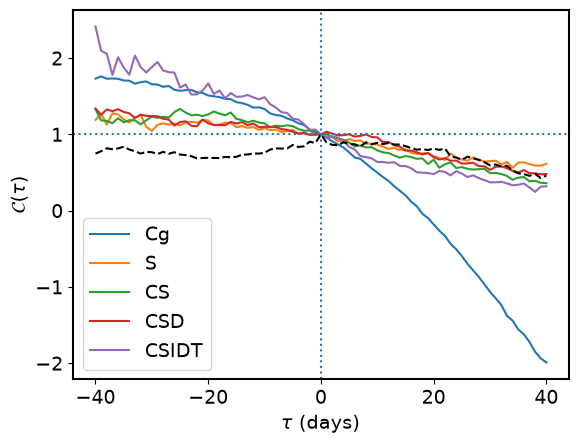

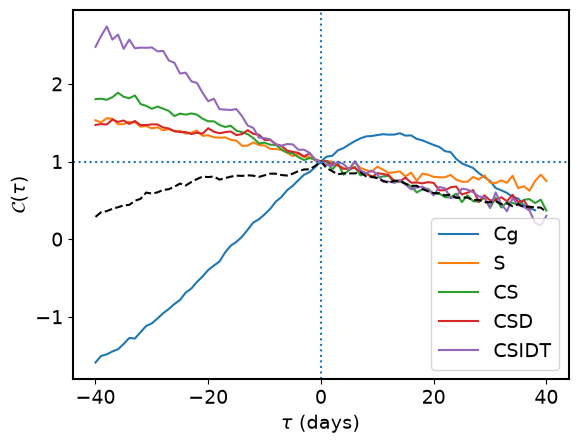

In [22]:
jj=18

plt.plot(np.arange(-win,win+1),series_Cg[-1].ac1['didi'][:,jj],label='Cg')
plt.plot(np.arange(-win,win+1),series_S[-1].ac1['didi'][:,jj],label='S')
plt.plot(np.arange(-win,win+1),series_CS[-1].ac1['didi'][:,jj],label='CS')
plt.plot(np.arange(-win,win+1),series_CSD[1].ac1['didi'][:,jj],label='CSD')
plt.plot(np.arange(-win,win+1),series_CSIDT[1].ac1['didi'][:,jj],label='CSIDT')
plt.plot(np.arange(-win,win+1),ac1_obs['dIdI'],color='k',linestyle='dashed')
plt.axhline(1,linestyle='dotted')
plt.axvline(0,linestyle='dotted')
plt.legend()
plt.xlabel(r'$\tau\ \mathrm{(days)}$')
plt.ylabel(r'$\mathcal{C}(\tau)$')
plt.savefig('ac_S_CS_CSD_7nov20.pdf')
plt.show()

plt.plot(np.arange(-win,win+1),series_Cg[-1].ac2['didi'][:,jj],label='Cg')
plt.plot(np.arange(-win,win+1),series_S[-1].ac2['didi'][:,jj],label='S')
plt.plot(np.arange(-win,win+1),series_CS[-1].ac2['didi'][:,jj],label='CS')
plt.plot(np.arange(-win,win+1),series_CSD[1].ac2['didi'][:,jj],label='CSD')
#plt.plot(np.arange(-win,win+1),res_CSID.ac2['didi'][:,jj],label='CSID')
plt.plot(np.arange(-win,win+1),series_CSIDT[1].ac2['didi'][:,jj],label='CSIDT')
plt.plot(np.arange(-win,win+1),ac2_obs['dIdI'],color='k',linestyle='dashed')
plt.axhline(1,linestyle='dotted')
plt.axvline(0,linestyle='dotted')
plt.legend()
plt.xlabel(r'$\tau\ \mathrm{(days)}$')
plt.ylabel(r'$\mathcal{C}(\tau)$')
plt.savefig('ac_S_CS_CSD_18dec20.pdf')
plt.show()


Plots for Series CgR

Matching fraction of cumulative infections relative to outbreak size for data and simulations.
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.064144
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.065404
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.076752
Matching fraction 0.665598 of outbreak size.
Current outbreak size in model: 0.054276


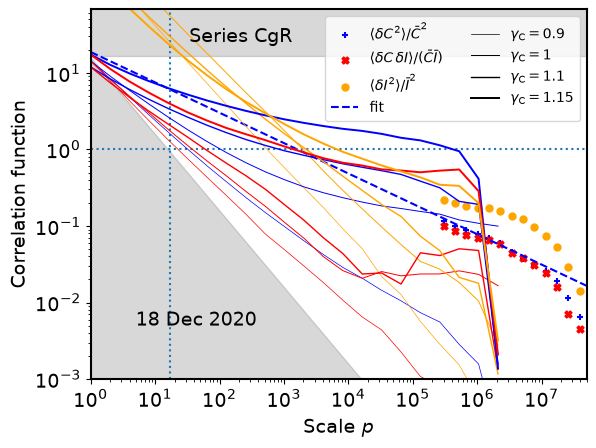

Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.
Showing model spectrum at scale p=262144.


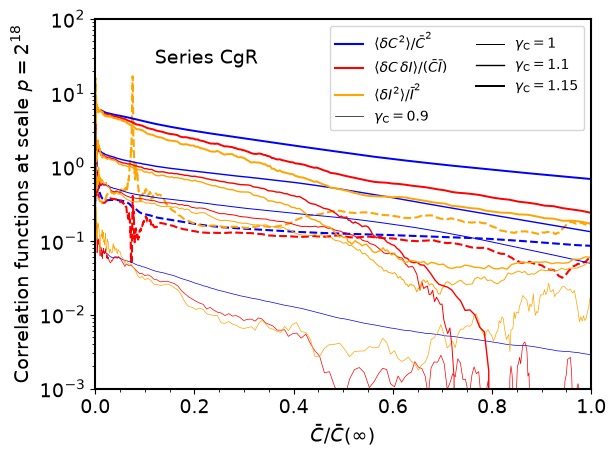

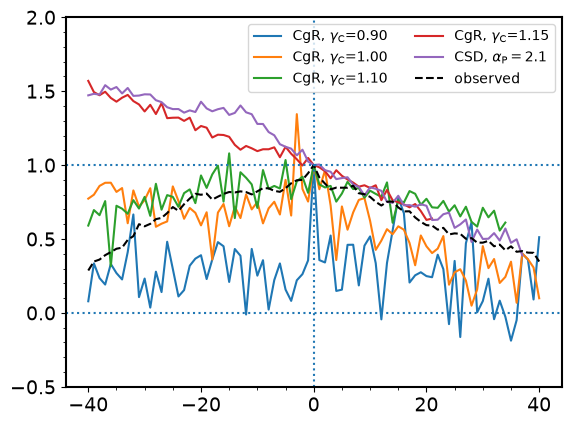

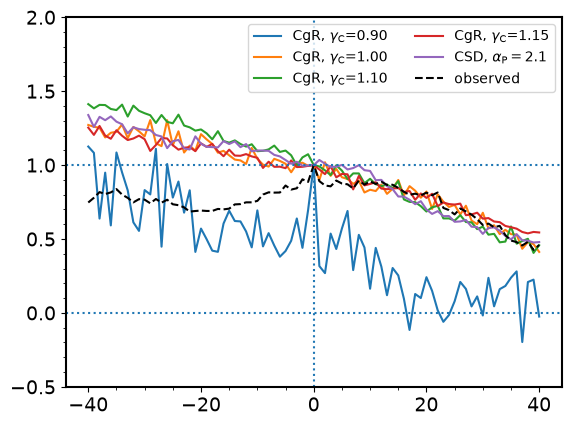

In [23]:
model.plot_spectra(rki_data, ii_18_dec_20, ii_25_feb_21,  series_CgR[:], \
                   variable = (r'\gamma_\mathrm{C}','gamma_c'), \
                   reporting_factor=3, norm='relative',\
                   label = 'CgR', ncol=2)

model.plot_spec_fixed_scale(rki_data, ii_25_feb_21, series_CgR[:], \
                            variable = (r'\gamma_\mathrm{C}','gamma_c'), \
                            logx=False, p_sim=18, label='CgR', ncol=2)
plt.ylim(1e-3,1e2)
plt.savefig('fluc_time_p22_CgR.pdf')
plt.show()

jj=18


for ii in [0,1,2,3]:
    plt.plot(np.arange(-win,win+1),series_CgR[ii].ac2['didi'][:,jj],label=r'CgR, $\gamma_\mathrm{C}$=%3.2f' % series_CgR[ii].gamma_c)
#plt.plot(np.arange(-win,win+1),series_CSD[2].ac2['didi'][:,18],label='CSD')
plt.plot(np.arange(-win,win+1),series_CSD[1].ac2['didi'][:,18],label=r'CSD, $\alpha_\mathrm{P}=2.1$')
plt.plot(np.arange(-win,win+1),ac2_obs['dIdI'],color='k',linestyle='dashed',label='observed')
plt.axhline(1,linestyle='dotted')
plt.axhline(0,linestyle='dotted')
plt.axvline(0,linestyle='dotted')
plt.legend(fontsize=10,ncol=2)
plt.ylim(-0.5,2)
plt.minorticks_on()
plt.savefig('autocorrelation_cgr.pdf')
plt.show()

for ii in [0,1,2,3]:
    plt.plot(np.arange(-win,win+1),series_CgR[ii].ac1['didi'][:,jj],label=r'CgR, $\gamma_\mathrm{C}$=%3.2f' % series_CgR[ii].gamma_c)
#plt.plot(np.arange(-win,win+1),series_CSD[2].ac2['didi'][:,18],label='CSD')
plt.plot(np.arange(-win,win+1),series_CSD[1].ac1['didi'][:,18],label=r'CSD, $\alpha_\mathrm{P}=2.1$')
plt.plot(np.arange(-win,win+1),ac1_obs['dIdI'],color='k',linestyle='dashed',label='observed')
plt.axhline(1,linestyle='dotted')
plt.axhline(0,linestyle='dotted')
plt.axvline(0,linestyle='dotted')
plt.legend(fontsize=10,ncol=2)
plt.ylim(-0.5,2)
plt.minorticks_on()
plt.savefig('autocorrelation_cgr_early.pdf')
plt.show()

In [24]:
# How much did we have to reduce the original number of live infections in these models?
for m in series_CgR:
    print ((m.I[0]/m.npop) / (3*rki_data.Iav[183,0]))

0.9501444384085255
0.2859658018511096
0.12453349435451548
0.032286461499318825


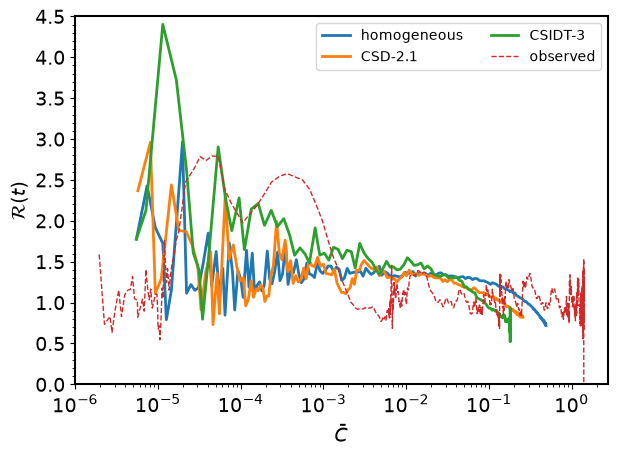

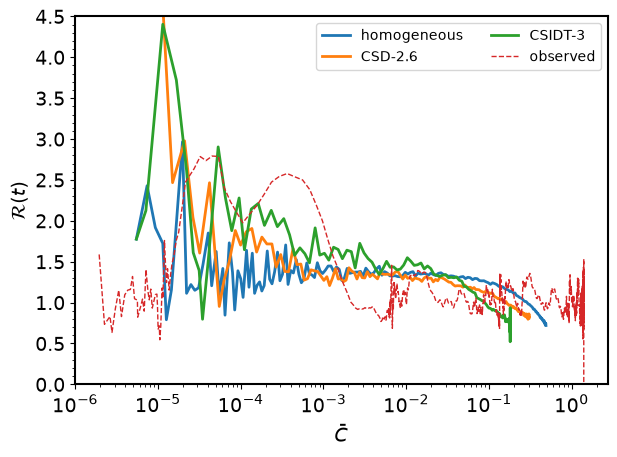

In [25]:
for csd_model in series_CSD[1:3]:
    plt.plot(series_C[0].C,series_C[0].Rt,linewidth=2,label='homogeneous')
    plt.plot(csd_model.C,csd_model.Rt, linewidth=2, label = 'CSD-%1.1f' % csd_model.alpha_pareto)
    ii = 2
    plt.plot(series_CSIDT[ii].C,series_CSIDT[ii].Rt,linewidth=2,label='CSIDT-3')
    plt.plot(rki_data.Cav[4:,-1]*3,rki_data.Iav[4:,-1]/rki_data.Iav[:-4,-1],\
             linewidth=1,linestyle='dashed',label='observed')
    plt.legend(fontsize=10,ncol=2)
    plt.xscale('log')
    plt.xlabel(r'$\bar{C}$')
    plt.ylim(0,4.5)
    plt.minorticks_on()
    plt.ylabel(r'$\mathcal{R}(t)$')
    plt.tight_layout()
    plt.savefig('Rt_vs_C_comp_CSD-%1.1f.pdf' % csd_model.alpha_pareto)
    plt.show()

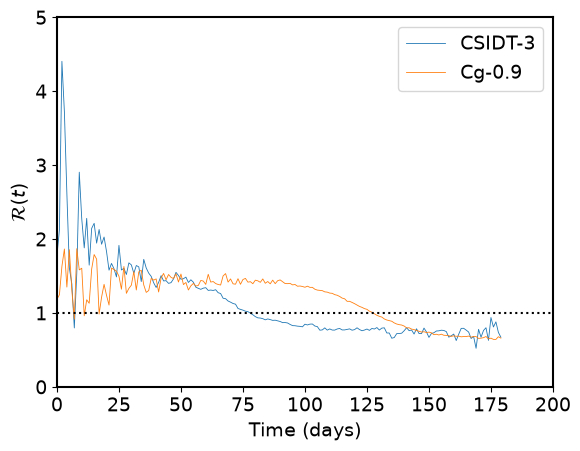

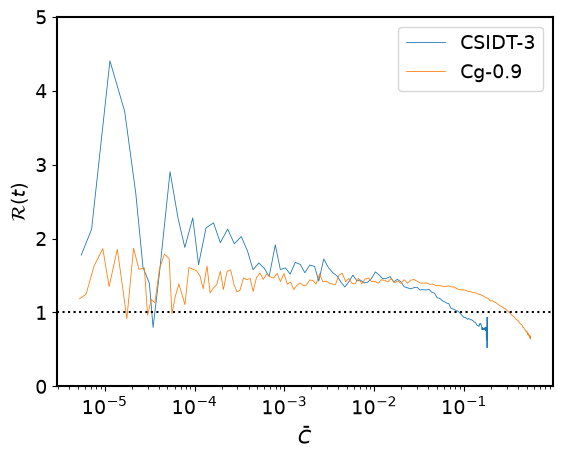

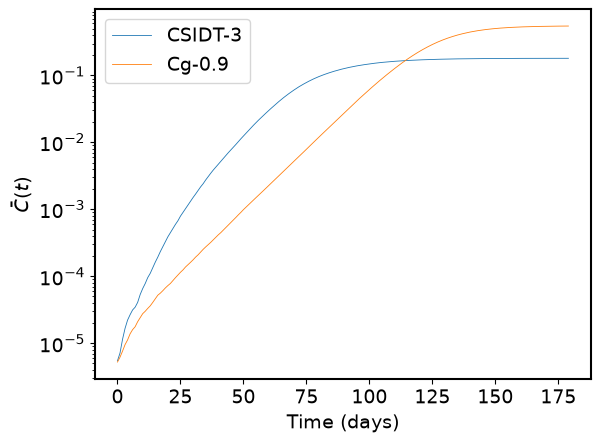

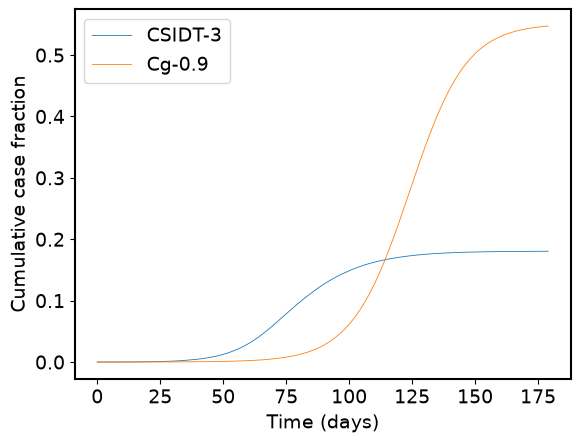

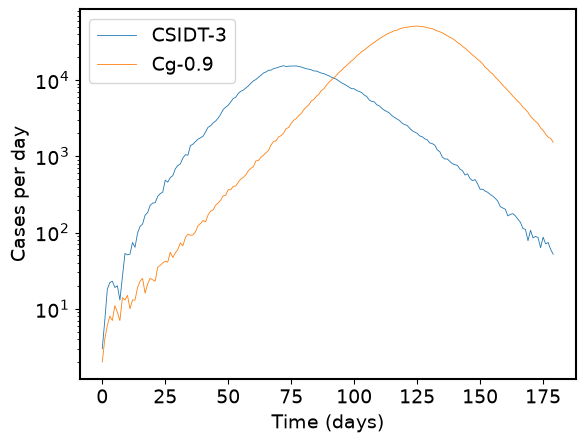

In [26]:
# Some additional plots for illustration purposes
model.plot_models ([series_CSIDT[2],series_Cg[3]],labels=['CSIDT-3','Cg-0.9'])

Summary tables

In [27]:
summary_latex(series_C, 'C', 'f_cluster', header = True)
summary_latex(series_Cg, 'Cg', 'gamma_c')
summary_latex(series_S, 'S', 'p_scal')
summary_latex(series_CS, 'CS', 'p_scal')
summary_latex(series_CSI, 'CSI', 'p_sus')
summary_latex(series_CD, 'CD', 'alpha_pareto')
summary_latex(series_CSD, 'CSD', 'alpha_pareto')
summary_latex(series_CSIDT, 'CSIDT', 'k_tra')
summary_latex(series_CgR, 'CgR', 'gamma_c')

 & $f_\mathrm{c}$ & $\gamma_\mathrm{c}$ & $\gamma_\mathrm{r}$ & $\delta$ & $\theta$ & $\alpha_\mathrm{P}$ & $k_\mathrm{tra}$ & avg.\ deg. & $R_\mathrm{C}$ & $C(\infty)$ & $C(\infty)/C_0$ &     SAR & $k_\mathrm{ovd}$ \\
\hline
 C-0.00 &    0.00 &    0.00 &    0.00 &    0.00 &     --- &     --- & --- &   12.00 &    1.37 &    0.49 &    0.99 &    0.00 &    3.55 \\
 C-0.30 &    0.30 &    0.00 &    0.00 &    0.00 &     --- &     --- & --- &   12.40 &    1.39 &    0.53 &    1.06 &    0.12 &    2.69 \\
 C-0.80 &    0.80 &    0.00 &    0.00 &    0.00 &     --- &     --- & --- &   12.32 &    1.37 &    0.59 &    1.22 &    0.13 &    2.21 \\
 C-0.90 &    0.90 &    0.00 &    0.00 &    0.00 &     --- &     --- & --- &   12.05 &    1.34 &    0.61 &    1.33 &    0.16 &    1.83 \\
 C-0.95 &    0.95 &    0.00 &    0.00 &    0.00 &     --- &     --- & --- &   12.45 &    1.37 &    0.79 &    1.62 &    0.20 &    1.30 \\
\hline
 Cg-0.00 &    0.00 &    0.00 &    0.00 &    0.00 &     --- &     --- & --- &   12.

In [28]:
print("Series C")
summary(series_C, 'f_cluster', 'f_C')

print("\nSeries Cg")
summary(series_Cg, 'gamma_c', 'γ_c')

print("\nSeries S")
summary(series_S, 'p_scal', 'p_scal')

print("\nSeries CS")
summary(series_CS, 'p_scal', 'p_scal')

print("\nSeries CSI")
summary(series_CSI, 'p_sus', 'p_sus')

print("\nSeries CD")
summary(series_CD, 'alpha_pareto', 'α')

print("\nSeries CSD")
summary(series_CSD, 'alpha_pareto', 'α')

print("\nSeries CSIDT")
summary(series_CSIDT, 'k_tra', 'k_tra')

print("\nSeries CgR")
summary(series_CgR, 'gamma_c', 'γ_c')

Series C
    f_C     R_C    C(∞) C(∞)/C0     SAR       k av.deg.
   0.00    1.37    0.49    0.99    0.00    3.55   12.00
   0.30    1.39    0.53    1.06    0.12    2.69   12.40
   0.80    1.37    0.59    1.22    0.13    2.21   12.32
   0.90    1.34    0.61    1.33    0.16    1.83   12.05
   0.95    1.37    0.79    1.62    0.20    1.30   12.45

Series Cg
    γ_c     R_C    C(∞) C(∞)/C0     SAR       k av.deg.
   0.00    1.37    0.49    0.99    0.00    3.55   12.00
   0.30    1.39    0.52    1.03    0.00    3.14   12.00
   0.60    1.43    0.53    0.99    0.00    2.96   12.00
   0.90    1.43    0.55    1.02    0.10    2.60   11.97
   1.10    1.44    0.65    1.21    0.27    1.99   11.53
   1.20    1.41    0.73    1.39    0.34    1.75   10.93

Series S
 p_scal     R_C    C(∞) C(∞)/C0     SAR       k av.deg.
   0.00    1.37    0.49    0.99    0.00    3.55   12.00
   0.04    1.39    0.51    1.02    0.00    3.23   12.00
   0.08    1.42    0.49    0.94    0.00    3.23   12.00
   0.12    1.42   